# WNMFDDA: supporting arguments S1, S2, S3 (deterministic checks)

Companion notebook to *Wang et al., "A weighted non-negative matrix factorization approach to predict potential associations between drug and disease", J Transl Med 2022, 20:552*.

It tests the three **architecture-derived** arguments that *support* the model. Every check follows the same framework, so the three cases (and the three rejecting cases, to be added later) are directly comparable.

| Step | Meaning |
|---|---|
| **E** | Governing equations (paper numbering) |
| **P** | Proposition that follows from them |
| **Q** | The quantity computed from `Y`, `S^R`, `S^D` and the factors |
| **V** | Deterministic pass/fail rule (checked on Fdataset and Cdataset at the paper's parameters) |
| **L** | Optional link to a downstream effect through one ablation |

| Case | Statement | Scope of the verdict |
|---|---|---|
| **S1** | WKNN reconstruction preserves observed labels and stays bounded | Implementation invariant, **not** proof of predictive benefit |
| **S2** | The multiplicative updates decrease the objective | Checks the optimisation algorithm, **not** generalisation |
| **S3** | The regularised factorisation has well-conditioned block curvature | Per-block strong convexity only; **not** joint convexity or a global optimum |

**Running on Kaggle.** Upload `DataF.mat` and `DataC.mat` as a Kaggle Dataset and attach it to the notebook. The loader searches `/kaggle/input` recursively. CPU is enough. The full run (20 seeds x 2 datasets x up to 1000 iterations) takes roughly 10 to 20 minutes. Set `QUICK = True` in the next cell for a 2-minute smoke test.

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import scipy.io as sio
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:          # plain python
    display = print

# ------------------------------------------------------------------ configuration
QUICK     = os.environ.get("QUICK", "0") == "1"   # True = smoke test (3 seeds, 100 iterations)
DATASETS  = ["F", "C"]                            # Fdataset, Cdataset
N_SEEDS   = 3 if QUICK else 20                    # S2: random initialisations per dataset
MAX_ITER  = 100 if QUICK else 1000                # S2: iteration cap per run (WNMFDDA.m usually stops near 700)
STOP_TOL  = 1e-4                                  # stopping rule of WNMFDDA.m
PARAMS    = dict(K=5, a=0.5, p=5, k=160, lam=1.0, beta=0.02)   # the paper's optimum
RTOL_MONO = 1e-10                                 # S2: an increase counts only above this relative size
KKT_REDUCTION = 0.1                               # S2: KKT residual must fall to <= 10% of its initial value
KKT_EVERY = 10                                    # S2: evaluate the KKT residual every N iterations
DATA_DIR  = os.environ.get("DATA_DIR")            # optional manual override of the data folder

RESULTS = []                                      # every verdict is collected here
def record(case, check, value, criterion, ok):
    RESULTS.append(dict(case=case, check=check, value=value, criterion=criterion,
                        verdict="PASS" if ok else "FAIL"))
print("QUICK =", QUICK, "| seeds =", N_SEEDS, "| max_iter =", MAX_ITER, "|", PARAMS)

QUICK = False | seeds = 20 | max_iter = 1000 | {'K': 5, 'a': 0.5, 'p': 5, 'k': 160, 'lam': 1.0, 'beta': 0.02}


## 0. Data

`DataF.mat` / `DataC.mat` store `Y` as **diseases x drugs** (313 x 593 for Fdataset). The paper (and the corrected `WNMFDDA.m`) use **drugs x diseases** ($Y \in R^{n\times m}$, $A \in R^{k\times n}$, $B \in R^{k\times m}$), so `Y` is transposed once, here. $S^R$ is $n\times n$ (drugs) and $S^D$ is $m\times m$ (diseases).

In [2]:
def find_mat(name):
    roots = [DATA_DIR, "/kaggle/input", ".", "/mnt/user-data/uploads"]
    for r in roots:
        if r and os.path.isdir(r):
            hits = sorted(glob.glob(os.path.join(r, "**", "*" + name), recursive=True))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found. Attach it as a Kaggle Dataset or set DATA_DIR.")

def load_dataset(tag):
    path = find_mat(f"Data{tag}.mat")
    D = sio.loadmat(path)
    Y, SR, SD = (D[k].astype(float) for k in ("Y", "SR", "SD"))
    n, m = SR.shape[0], SD.shape[0]
    if Y.shape == (m, n):
        Y = Y.T                                   # diseases x drugs  ->  drugs x diseases
    assert Y.shape == (n, m), f"unexpected shapes {Y.shape}, {SR.shape}, {SD.shape}"
    assert set(np.unique(Y)) <= {0.0, 1.0}, "Y must be binary"
    assert np.allclose(SR, SR.T) and np.allclose(SD, SD.T), "similarity matrices must be symmetric"
    return dict(tag=tag, path=path, Y=Y, SR=SR, SD=SD, n=n, m=m)

DATA = {t: load_dataset(t) for t in DATASETS}
display(pd.DataFrame([dict(dataset=t + "dataset", drugs_n=d["n"], diseases_m=d["m"],
                           associations=int(d["Y"].sum()),
                           density_pct=round(100 * d["Y"].mean(), 3),
                           file=os.path.basename(d["path"])) for t, d in DATA.items()]))

,dataset,drugs_n,diseases_m,associations,density_pct,file
0,Fdataset,593,313,1933,1.041,DataF.mat
1,Cdataset,663,409,2532,0.934,DataC.mat


## Shared implementation

A line-for-line port of the corrected `Graph.m`, `WKNN.m` and `WNMFDDA.m`: Eq. 8 to 10 (sparse graphs), Eq. 1 to 5 (WKNN), Eq. 15 (objective), Eq. 17 and 18 (gradients), Eq. 21 and 22 (updates).

In [3]:
EPS = np.finfo(float).eps

# ---------------------------------------------------------------- Eq. 8-10: sparse p-NN graph
def graph_W(S, p):
    n = S.shape[0]
    S = S.copy(); np.fill_diagonal(S, -np.inf)                    # an item is never its own neighbour
    idx = np.argsort(-S, axis=1, kind="stable")[:, :p]
    N = np.zeros((n, n), bool)
    N[np.repeat(np.arange(n), p), idx.ravel()] = True             # N[i,j]  <=>  j in N_p(i)
    W = np.full((n, n), 0.5)                                      # "otherwise" branch of Eq. 8
    W[N & N.T] = 1.0                                              # mutual neighbours
    W[~N & ~N.T] = 0.0                                            # neither is a neighbour
    return W

def build_graph_terms(SR, SD, p):
    SRs, SDs = SR * graph_W(SR, p), SD * graph_W(SD, p)           # Eq. 9, 10  (S^{R*}, S^{D*})
    dr, dd = SRs.sum(1), SDs.sum(1)                               # diagonals of D_r, D_d
    Lr, Ld = np.diag(dr) - SRs, np.diag(dd) - SDs                 # L = D - S*
    return dict(SRs=SRs, SDs=SDs, dr=dr, dd=dd, Lr=Lr, Ld=Ld,
                LmaxR=np.linalg.eigvalsh(Lr)[-1], LmaxD=np.linalg.eigvalsh(Ld)[-1])

# ---------------------------------------------------------------- Eq. 1-5: WKNN
def neighbor_profile(Y, S, K, a):
    # row i of the result = weighted KNN profile of item i (rows of Y are the items)
    S = S.copy(); np.fill_diagonal(S, -np.inf)
    idx = np.argsort(-S, axis=1, kind="stable")[:, :K]            # K most similar items, descending
    s = np.maximum(np.take_along_axis(S, idx, axis=1), 0.0)       # S(r_i, r_p)
    w = (a ** np.arange(K))[None, :] * s                          # w_i = a^(i-1) * S(r_i, r_p)   (Eq. 2, 4)
    den = s.sum(1, keepdims=True)                                 # sum_{i<=K} S(r_i, r_p)
    num = np.einsum("ik,ikm->im", w, Y[idx])
    ok = den > 0
    Yp = np.divide(num, den, out=np.zeros_like(num), where=ok)    # Eq. 1, 3
    cap = np.divide(w.sum(1, keepdims=True), den, out=np.zeros_like(den), where=ok).ravel()
    return Yp, idx, w, cap          # cap_i = sum a^(i-1) S_i / sum S_i = the largest value row i of Yp can reach

def wknn(Y, SR, SD, K, a):
    Yr, idx_r, w_r, cap_r = neighbor_profile(Y,   SR, K, a)       # drugs    (rows)
    Yd_T, idx_d, w_d, cap_d = neighbor_profile(Y.T, SD, K, a)     # diseases (columns)
    Yd = Yd_T.T
    Yrd = (Yr + Yd) / 2                                           # Algorithm step 3
    return dict(Yr=Yr, Yd=Yd, Yrd=Yrd, Yp=np.maximum(Y, Yrd),     # Eq. 5: Y' = max(Y, Y_rd)
                idx_r=idx_r, w_r=w_r, cap_r=cap_r, idx_d=idx_d, w_d=w_d, cap_d=cap_d)

# ---------------------------------------------------------------- Eq. 15, 17, 18, 21, 22
def objective(A, B, Y, G, lam, beta):
    R = Y - A.T @ B
    return ((R * R).sum()
            + lam * (((A @ G["Lr"]) * A).sum() + ((B @ G["Ld"]) * B).sum())
            + beta * ((A * A).sum() + (B * B).sum()))

def grad_A(A, B, Y, G, lam, beta):                                # Eq. 17 without Phi
    return 2 * ((B @ B.T) @ A - B @ Y.T + lam * (A @ G["Lr"]) + beta * A)

def grad_B(A, B, Y, G, lam, beta):                                # Eq. 18 without Psi
    return 2 * ((A @ A.T) @ B - A @ Y + lam * (B @ G["Ld"]) + beta * B)

def update_A(A, B, Y, G, lam, beta):                              # Eq. 21
    num = B @ Y.T + lam * (A @ G["SRs"])
    den = (B @ B.T) @ A + lam * (A * G["dr"][None, :]) + beta * A
    return A * (num / np.maximum(den, EPS))

def update_B(A, B, Y, G, lam, beta):                              # Eq. 22 (uses the updated A)
    num = A @ Y + lam * (B @ G["SDs"])
    den = (A @ A.T) @ B + lam * (B * G["dd"][None, :]) + beta * B
    return B * (num / np.maximum(den, EPS))

# ---------------------------------------------------------------- projected-gradient KKT residual
def kkt_residual(A, B, Y, G, lam, beta):
    # r_A = || A - max(0, A - g_A / L_A) ||_inf  with the step 1/L_A, L_A = Lipschitz constant of g_A,
    # so that the residual is scale-aware.  The relative version divides by ||A||_inf.
    LA = 2 * (np.linalg.eigvalsh(B @ B.T)[-1] + lam * G["LmaxR"] + beta)
    LB = 2 * (np.linalg.eigvalsh(A @ A.T)[-1] + lam * G["LmaxD"] + beta)
    rA = np.abs(A - np.maximum(0.0, A - grad_A(A, B, Y, G, lam, beta) / LA)).max()
    rB = np.abs(B - np.maximum(0.0, B - grad_B(A, B, Y, G, lam, beta) / LB)).max()
    return rA, rB, rA / max(np.abs(A).max(), 1e-300), rB / max(np.abs(B).max(), 1e-300)

# ---------------------------------------------------------------- full WNMFDDA run with diagnostics
def run_wnmfdda(Y, G, k, lam, beta, max_iter, seed, tol=STOP_TOL, kkt_every=KKT_EVERY):
    rng = np.random.default_rng(seed)
    n, m = Y.shape
    A, B = rng.random((k, n)), rng.random((k, m))                 # step 6: random non-negative init
    F = [objective(A, B, Y, G, lam, beta)]
    incA, incB, minA, minB, kkt = [], [], [], [], [(0,) + kkt_residual(A, B, Y, G, lam, beta)]
    for it in range(1, max_iter + 1):
        U = update_A(A, B, Y, G, lam, beta);  F1 = objective(U, B, Y, G, lam, beta)   # after the A-step
        V = update_B(U, B, Y, G, lam, beta);  F2 = objective(U, V, Y, G, lam, beta)   # after the B-step
        incA.append(F1 - F[-1]); incB.append(F2 - F1); F.append(F2)
        minA.append(U.min()); minB.append(V.min())
        err = max((((U - A) ** 2).sum(0)).max(), (((V - B) ** 2).sum(0)).max())      # WNMFDDA.m stopping rule
        A, B = U, V
        if it % kkt_every == 0:
            kkt.append((it,) + kkt_residual(A, B, Y, G, lam, beta))
        if err < tol:
            break
    if kkt[-1][0] != it:
        kkt.append((it,) + kkt_residual(A, B, Y, G, lam, beta))
    return dict(F=np.array(F), incA=np.array(incA), incB=np.array(incB), minA=min(minA), minB=min(minB),
                kkt=np.array(kkt), iters=it, converged=err < tol, A=A, B=B)

---
## S1. WKNN reconstruction preserves observed labels and stays bounded

**E.** Eq. 1 to 5:
$Y_r(r_p)=\frac{1}{\sum_{i\le K}S^R(r_i,r_p)}\sum_{i=1}^{K}w_iY(r_i)$ with $w_i=a^{i-1}S^R(r_i,r_p)$, the analogous $Y_d$ for diseases, $Y_{rd}=(Y_r+Y_d)/2$, and $Y'=\max(Y,Y_{rd})$.

**P.** For binary $Y$, $a\in[0,1]$ and non-negative similarities:

1. $Y' \ge Y$ entrywise, and every observed association is preserved: $Y_{ij}=1 \Rightarrow Y'_{ij}=1$.
2. $0 \le Y' \le 1$.
3. Sharp bound for unobserved pairs: $Y'_{ij}\le \tfrac12\,(c^R_i + c^D_j)$, where $c_i=\sum_t a^{t-1}S_t / \sum_t S_t \le 1$ is the largest value row $i$ of $Y_r$ can reach.
4. **Strictness is conditional, not unconditional.** $Y'_{ij}<1$ for an unobserved pair is guaranteed only where $\tfrac12(c^R_i+c^D_j)<1$. That needs $a<1$ *and* positive similarity weight on at least a second neighbour (so more than one neighbour contributes) in at least one of the two profiles. With $a=1$, $K=1$, or a single positive-similarity neighbour, an unobserved entry can legitimately reach 1. The strict inequality is therefore **not** asserted unconditionally; it is checked only where its condition holds, and the entries outside the condition are counted.
5. Cold start: if a drug (or disease) has an all-zero row (column), its row in $Y'$ has support exactly equal to the union of the supports of its positively weighted neighbours.

**Q.** Items 1 to 5, computed on Fdataset and Cdataset at $K=5$, $a=0.5$. Item 5 zeroes 25 random rows and 25 random columns of a copy of $Y$.

**V.** Items 1, 2, 3, 5 hold exactly. Item 4 holds on every entry where its condition holds (the count of entries outside the condition is reported). 

**L.** None. This is an implementation invariant of the preprocessing, not evidence of predictive benefit.

In [4]:
def s1_check(D, K, a, n_cold=25, seed=0):
    Y, SR, SD = D["Y"], D["SR"], D["SD"]
    W = wknn(Y, SR, SD, K, a)
    Yp = W["Yp"]
    known, unk = Y == 1, Y == 0
    cap = (W["cap_r"][:, None] + W["cap_d"][None, :]) / 2
    cond = unk & (cap < 1 - 1e-12)                       # entries where strictness is guaranteed
    out = {}
    out["1a  Y' >= Y"]                      = bool((Yp >= Y).all())
    out["1b  known 1s preserved"]           = bool((Yp[known] == 1).all())
    out["2   0 <= Y' <= 1"]                 = bool(Yp.min() >= 0 and Yp.max() <= 1 + 1e-12)
    out["3   Y' <= (c_R + c_D)/2 (unknowns)"] = bool((Yp[unk] <= cap[unk] + 1e-12).all())
    out["4   Y' < 1 where condition holds"] = bool((Yp[cond] < 1).all())
    info = dict(unknown_pairs=int(unk.sum()),
                strict_guaranteed=int(cond.sum()),
                outside_condition=int((unk & ~cond).sum()),
                unknowns_reaching_1=int((Yp[unk] >= 1 - 1e-12).sum()),
                reach_1_inside_condition=int(((Yp >= 1 - 1e-12) & cond).sum()),
                drugs_with_cap_1=int((W["cap_r"] >= 1 - 1e-12).sum()),
                diseases_with_cap_1=int((W["cap_d"] >= 1 - 1e-12).sum()),
                zero_rows_raw=int((Y.sum(1) == 0).sum()), zero_cols_raw=int((Y.sum(0) == 0).sum()),
                zero_rows_after=int((Yp.sum(1) == 0).sum()), zero_cols_after=int((Yp.sum(0) == 0).sum()))

    # item 5: cold start, support = union of the supports of the positively weighted neighbours
    rng = np.random.default_rng(seed)
    n, m = Y.shape
    rows = rng.choice(np.where(Y.sum(1) > 0)[0], n_cold, replace=False)
    cols = rng.choice(np.where(Y.sum(0) > 0)[0], n_cold, replace=False)
    Y0 = Y.copy(); Y0[rows, :] = 0; Y0[:, cols] = 0
    W0 = wknn(Y0, SR, SD, K, a); Yp0 = W0["Yp"]
    ok_rows = ok_cols = True; became_nonzero = 0
    for i in rows:
        nb = W0["idx_r"][i][W0["w_r"][i] > 0]
        expected = (Y0[nb, :] != 0).any(0)
        ok_rows &= bool(np.array_equal(Yp0[i] > 0, expected)); became_nonzero += int(expected.any())
    for j in cols:
        nb = W0["idx_d"][j][W0["w_d"][j] > 0]
        expected = (Y0[:, nb] != 0).any(1)
        ok_cols &= bool(np.array_equal(Yp0[:, j] > 0, expected)); became_nonzero += int(expected.any())
    out["5   cold-start support = union of neighbours"] = ok_rows and ok_cols
    info["cold_items_tested"] = 2 * n_cold
    info["cold_items_with_nonzero_profile"] = became_nonzero
    return out, info

rows_out, info_out = [], {}
for t, D in DATA.items():
    checks, info = s1_check(D, PARAMS["K"], PARAMS["a"])
    info_out[t] = info
    for name, ok in checks.items():
        rows_out.append(dict(dataset=t + "dataset", check=name, result="PASS" if ok else "FAIL"))
        record("S1", f"{t}: {name}", ok, "holds exactly" if not name.startswith("4") else "holds where condition holds", ok)
display(pd.DataFrame(rows_out).pivot(index="check", columns="dataset", values="result"))
print("Supporting counts (strictness is only guaranteed on the entries where its condition holds):")
display(pd.DataFrame(info_out).rename(columns=lambda t: t + "dataset"))

dataset,Cdataset,Fdataset
check,,
1a Y' >= Y,PASS,PASS
1b known 1s preserved,PASS,PASS
2 0 <= Y' <= 1,PASS,PASS
3 Y' <= (c_R + c_D)/2 (unknowns),PASS,PASS
4 Y' < 1 where condition holds,PASS,PASS
5 cold-start support = union of neighbours,PASS,PASS


Supporting counts (strictness is only guaranteed on the entries where its condition holds):


,Fdataset,Cdataset
unknown_pairs,183676,268635
strict_guaranteed,183676,268635
outside_condition,0,0
unknowns_reaching_1,0,0
reach_1_inside_condition,0,0
drugs_with_cap_1,0,0
diseases_with_cap_1,0,0
zero_rows_raw,0,0
zero_cols_raw,0,0
zero_rows_after,0,0


**Reading S1.** The five invariants confirm that the preprocessing of Eq. 1 to 5 behaves as intended: it never removes or lowers an observed association, it stays inside $[0,1]$, and a drug or disease with no associations receives a profile built from its neighbours. The strict inequality `Y' < 1` is reported only where its condition holds; any unobserved entries outside the condition (counted above) are allowed to reach 1 without contradicting the argument. This is an implementation invariant, not proof of predictive benefit.

---
## S2. The multiplicative updates decrease the objective

**E.** Objective (Eq. 15) $F(A,B)=\|Y'-A^TB\|_F^2+\lambda\,[\mathrm{Tr}(AL_rA^T)+\mathrm{Tr}(BL_dB^T)]+\beta(\|A\|_F^2+\|B\|_F^2)$ with $L=D-S^{*}$. Gradients (Eq. 17, 18 without the multipliers):

$\nabla_AF=2\,[\,BB^TA-BY'^T+\lambda AL_r+\beta A\,]$, $\qquad \nabla_BF=2\,[\,AA^TB-AY'+\lambda BL_d+\beta B\,]$.

Updates (Eq. 21, 22): $A\leftarrow A\odot\dfrac{BY'^T+\lambda AS^{R*}}{BB^TA+\lambda AD_r+\beta A}$ and $B\leftarrow B\odot\dfrac{AY'+\lambda BS^{D*}}{AA^TB+\lambda BD_d+\beta B}$.

**P.** Each update is $X\odot(\text{negative part of }\nabla F/2)/(\text{positive part of }\nabla F/2)$. Splitting the Laplacian into the non-negative matrices $D$ and $S^*$ puts the graph term into exactly that form. This is the auxiliary-function (Lee-Seung / graph-regularised NMF) setting, so each block update cannot increase $F$, the factors stay non-negative, and fixed points satisfy the KKT conditions of Eq. 19 and 20. The B-step uses the already-updated $A$, so the scheme is block-coordinate descent and each half-step is monotone.

**Q.** For 20 seeds per dataset, at paper parameters ($k=160$, $\lambda=1$, $\beta=0.02$):

1. $F$ after the **A-step** and after the **B-step** at every iteration. An increase is counted when it exceeds $10^{-10}\max(F,1)$.
2. $\min A$ and $\min B$ over all iterations.
3. The **projected-gradient KKT residual for both factors**, $r_A=\|A-\max(0,A-\nabla_AF/L_A)\|_\infty$ and $r_B$ likewise, where $L_A=2(\lambda_{\max}(BB^T)+\lambda\lambda_{\max}(L_r)+\beta)$ is the Lipschitz constant of $\nabla_AF$ (so the step is scale-aware). The relative residual divides by $\|A\|_\infty$ (resp. $\|B\|_\infty$). A residual such as $\max|A\odot\nabla_AF|$ alone is not used, because it does not check the sign condition $\nabla F\ge0$ at zero entries.

**V.** Zero objective increases in both half-steps; $\min A,\min B\ge0$; the relative KKT residuals of **both** $A$ and $B$ at the last checked iterate have fallen to at most `KKT_REDUCTION` (10%) of their value at the random start. The absolute final residual is reported but is *not* forced to zero: multiplicative updates guarantee monotone descent, and their limit points need not be KKT points (an entry that reaches zero while its gradient is negative cannot move again).

**L.** None. This checks the optimisation algorithm itself, not whether the model generalises.

In [4]:
# ---- small helpers (also reused by S3)
def small_problem(n=7, m=5, k=3, p=2, seed=0):
    rng = np.random.default_rng(seed)
    Y = (rng.random((n, m)) < 0.35).astype(float)
    def sym(d):
        S = rng.random((d, d)); S = (S + S.T) / 2; np.fill_diagonal(S, 1.0); return S
    return Y, build_graph_terms(sym(n), sym(m), p), rng

def fd_gradient(f, X, h=1e-6):
    g = np.zeros_like(X)
    for idx in np.ndindex(*X.shape):
        Xp, Xm = X.copy(), X.copy(); Xp[idx] += h; Xm[idx] -= h
        g[idx] = (f(Xp) - f(Xm)) / (2 * h)
    return g

# ---- sanity check: the analytic gradients (Eq. 17, 18) match finite differences of the objective (Eq. 15)
Ys, Gs, rg = small_problem()
As, Bs = rg.random((3, 7)), rg.random((3, 5))
lam_s, beta_s = PARAMS["lam"], PARAMS["beta"]
eA = np.abs(grad_A(As, Bs, Ys, Gs, lam_s, beta_s) - fd_gradient(lambda X: objective(X, Bs, Ys, Gs, lam_s, beta_s), As)).max()
eB = np.abs(grad_B(As, Bs, Ys, Gs, lam_s, beta_s) - fd_gradient(lambda X: objective(As, X, Ys, Gs, lam_s, beta_s), Bs)).max()
print(f"gradient check  max|analytic - finite difference|:  A {eA:.2e}   B {eB:.2e}")
record("S2", "gradients match finite differences", max(eA, eB), "< 1e-5", max(eA, eB) < 1e-5)

gradient check  max|analytic - finite difference|:  A 3.23e-09   B 2.52e-09


In [5]:
S2_ROWS, S2_CURVES = [], {}
for t, D in DATA.items():
    D["G"] = build_graph_terms(D["SR"], D["SD"], PARAMS["p"])
    D["Yprime"] = wknn(D["Y"], D["SR"], D["SD"], PARAMS["K"], PARAMS["a"])["Yp"]   # S1-verified input
    S2_CURVES[t] = []
    t0 = time.time()
    for seed in range(N_SEEDS):
        r = run_wnmfdda(D["Yprime"], D["G"], PARAMS["k"], PARAMS["lam"], PARAMS["beta"], MAX_ITER, seed)
        F = r["F"]
        thrA = RTOL_MONO * np.maximum(F[:-1], 1.0)                    # F before the A-step
        thrB = RTOL_MONO * np.maximum(F[:-1] + r["incA"], 1.0)        # F after the A-step
        vA, vB = int((r["incA"] > thrA).sum()), int((r["incB"] > thrB).sum())
        worst = float(max(np.max(r["incA"] / np.maximum(F[:-1], 1.0)), np.max(r["incB"] / np.maximum(F[:-1] + r["incA"], 1.0)), 0.0))
        k0, kf = r["kkt"][0], r["kkt"][-1]                            # columns: it, rA, rB, relA, relB
        S2_ROWS.append(dict(dataset=t, seed=seed, iters=r["iters"], converged=r["converged"],
                            F_start=F[0], F_end=F[-1], viol_A=vA, viol_B=vB, worst_rel_increase=worst,
                            min_A=r["minA"], min_B=r["minB"],
                            kkt_relA_0=k0[3], kkt_relB_0=k0[4], kkt_relA_end=kf[3], kkt_relB_end=kf[4]))
        S2_CURVES[t].append(dict(F=F, kkt=r["kkt"]))
        if seed == 0:
            D["final0"] = dict(A=r["A"], B=r["B"])                    # kept for S3
    print(f"{t}dataset: {N_SEEDS} seeds done in {time.time() - t0:.0f}s")

S2_DF = pd.DataFrame(S2_ROWS)
display(S2_DF.groupby("dataset").agg(runs=("seed", "count"), iters_mean=("iters", "mean"),
                                     converged=("converged", "sum"),
                                     viol_A=("viol_A", "sum"), viol_B=("viol_B", "sum"),
                                     worst_rel_increase=("worst_rel_increase", "max"),
                                     min_A=("min_A", "min"), min_B=("min_B", "min"),
                                     kkt_relA_0=("kkt_relA_0", "mean"), kkt_relA_end_max=("kkt_relA_end", "max"),
                                     kkt_relB_0=("kkt_relB_0", "mean"), kkt_relB_end_max=("kkt_relB_end", "max")))
for t in DATASETS:
    d = S2_DF[S2_DF.dataset == t]
    record("S2", f"{t}: objective increases in A-step (all seeds)", int(d.viol_A.sum()), "= 0", d.viol_A.sum() == 0)
    record("S2", f"{t}: objective increases in B-step (all seeds)", int(d.viol_B.sum()), "= 0", d.viol_B.sum() == 0)
    record("S2", f"{t}: min over A and B (all iterations)", float(min(d.min_A.min(), d.min_B.min())), ">= 0", min(d.min_A.min(), d.min_B.min()) >= 0)
    ra = float((d.kkt_relA_end / d.kkt_relA_0).max()); rb = float((d.kkt_relB_end / d.kkt_relB_0).max())
    record("S2", f"{t}: KKT residual A, end / start (worst seed)", ra, f"<= {KKT_REDUCTION}", ra <= KKT_REDUCTION)
    record("S2", f"{t}: KKT residual B, end / start (worst seed)", rb, f"<= {KKT_REDUCTION}", rb <= KKT_REDUCTION)

Fdataset: 20 seeds done in 251s
Cdataset: 20 seeds done in 332s


,runs,iters_mean,converged,viol_A,viol_B,worst_rel_increase,min_A,min_B,kkt_relA_0,kkt_relA_end_max,kkt_relB_0,kkt_relB_end_max
dataset,,,,,,,,,,,,
C,20,660.50,20,0,0,0.0,0.0,0.0,0.612946,0.023502,0.599458,0.019829
F,20,660.25,20,0,0,0.0,0.0,0.0,0.619539,0.037055,0.597338,0.021188


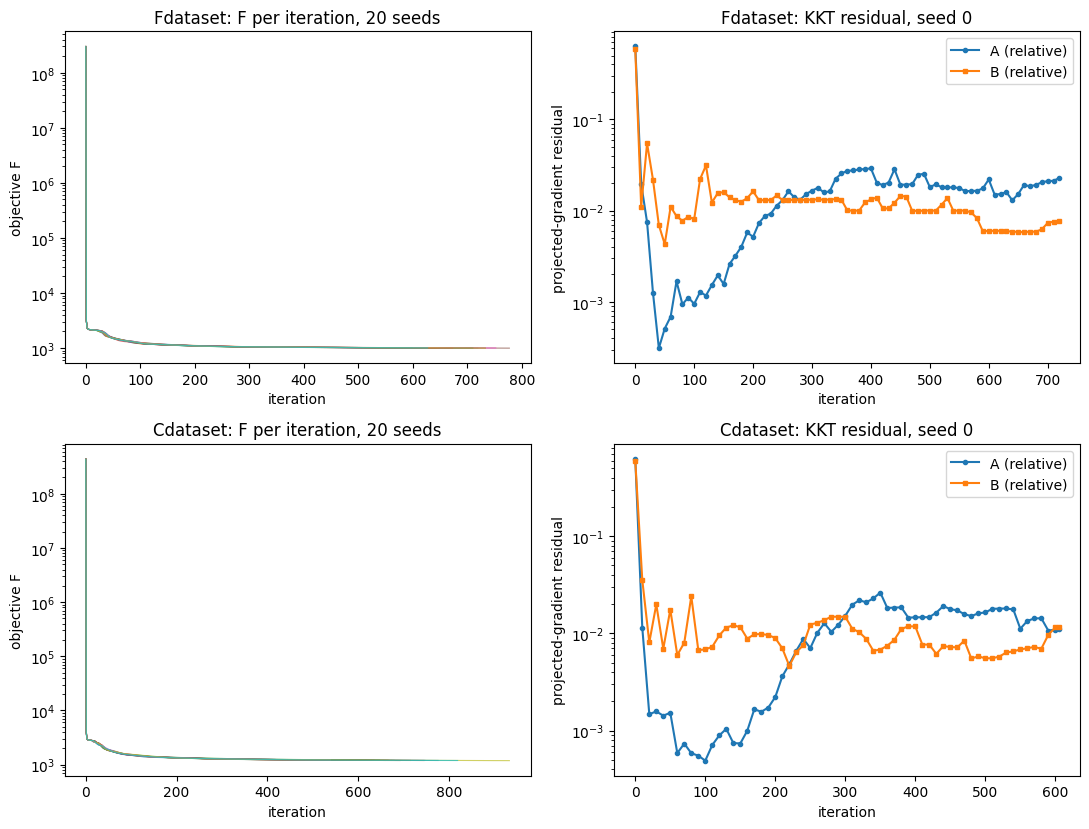

In [6]:
fig, axs = plt.subplots(len(DATASETS), 2, figsize=(11, 4.2 * len(DATASETS)), squeeze=False)
for row, t in enumerate(DATASETS):
    ax = axs[row, 0]
    for c in S2_CURVES[t]:
        ax.plot(c["F"], lw=0.8, alpha=0.7)
    ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("objective F")
    ax.set_title(f"{t}dataset: F per iteration, {N_SEEDS} seeds")
    ax = axs[row, 1]
    kk = S2_CURVES[t][0]["kkt"]
    ax.plot(kk[:, 0], kk[:, 3], "o-", ms=3, label="A (relative)")
    ax.plot(kk[:, 0], kk[:, 4], "s-", ms=3, label="B (relative)")
    ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("projected-gradient residual")
    ax.set_title(f"{t}dataset: KKT residual, seed 0"); ax.legend()
plt.tight_layout(); plt.show()

**Reading S2.** The counts above are the test: if the auxiliary-function argument applies to Eq. 21 and 22, both half-steps leave $F$ non-increasing and the factors non-negative on every seed. The projected-gradient residual shows how far the iterate is from a KKT point. It falls by more than an order of magnitude but need not reach zero and need not fall monotonically: multiplicative updates guarantee descent of $F$, not convergence to a KKT point (entries that reach zero while their gradient is negative cannot recover), so the absolute final residual is informative and is reported rather than forced below a threshold. Note that the stopping rule of `WNMFDDA.m` (column-wise change of the factors below $10^{-4}$) is not an objective-based rule, so it is not evidence of stationarity by itself. This verdict concerns the optimisation algorithm, not generalisation.

---
## S3. The regularised factorisation has well-conditioned block curvature

**E.** The objective of Eq. 15 and the Laplacians $L_r=D_r-S^{R*}$, $L_d=D_d-S^{D*}$ of Eq. 13 and 14.

**P.** With $S^*$ symmetric and non-negative, $L=D-S^*$ is symmetric positive semi-definite, since $x^TLx=\tfrac12\sum_{ij}S^*_{ij}(x_i-x_j)^2\ge0$, and $L\mathbf 1=0$. Fix $B$ and stack the columns of $A$ into $\mathrm{vec}(A)$. The Hessian of $F$ in the $A$-block is

$$H_A=2\,[\,I_n\otimes BB^T\;+\;\lambda\,L_r\otimes I_k\;+\;\beta I\,],\qquad H_B=2\,[\,I_m\otimes AA^T\;+\;\lambda\,L_d\otimes I_k\;+\;\beta I\,].$$

Its eigenvalues are $2(\mu_s+\lambda\ell_t+\beta)$ over all pairs, where $\mu_s\ge0$ are the eigenvalues of $BB^T$ and $\ell_t\ge0$ those of $L_r$. Hence, for $\beta>0$ and $\lambda\ge0$,

$$\lambda_{\min}(\nabla^2_AF)\ge2\beta,\qquad\lambda_{\min}(\nabla^2_BF)\ge2\beta,$$

with equality whenever $BB^T$ is singular (dead latent factors) because $\ell_{\min}=0$ always. Each block subproblem, with the other factor fixed, is therefore **strongly convex** and has a unique minimiser, with condition number at most $(\mu_{\max}+\lambda\ell_{\max}+\beta)/\beta$. **Scope:** this does *not* make the joint objective convex and does *not* guarantee a global optimum.

**Q.**
1. *Small cases* (where the full Kronecker Hessian can be built): compare the finite-difference Hessian with the formula above, check $\lambda_{\min}\ge2\beta$, and show $\lambda_{\min}=2\beta$ with dead factors and $0$ without $\beta$. Also evaluate the joint Hessian to show it can be indefinite.
2. *Full size*: no Kronecker matrix is built. $\lambda_{\min}$ and $\lambda_{\max}$ follow from the eigenvalues of the $k\times k$ matrix $BB^T$ (resp. $AA^T$) and of the graph Laplacian, at random initial factors and at the converged factors from S2. Also check that $L$ is symmetric positive semi-definite and that its null space equals the number of connected components of $S^*$.

**V.** The formula matches the finite-difference Hessian; $\lambda_{\min}\ge2\beta$ for both blocks in every case; $L$ is symmetric positive semi-definite with $L\mathbf 1=0$.

**L.** Ablation $\beta\to0$: the same eigenvalue formula shows $\lambda_{\min}$ collapsing to $2\mu_{\min}$ (zero with dead factors) and the condition-number bound becoming infinite.

In [7]:
def fd_hessian(grad_fn, X, h=1e-6):
    shp = X.shape; x0 = X.flatten(order="F"); N = x0.size; H = np.zeros((N, N))
    for i in range(N):
        e = np.zeros(N); e[i] = h
        gp = grad_fn((x0 + e).reshape(shp, order="F")).flatten(order="F")
        gm = grad_fn((x0 - e).reshape(shp, order="F")).flatten(order="F")
        H[:, i] = (gp - gm) / (2 * h)
    return (H + H.T) / 2

def formula_HA(B, G, lam, beta):
    k, n = B.shape[0], G["Lr"].shape[0]
    return 2 * (np.kron(np.eye(n), B @ B.T) + lam * np.kron(G["Lr"], np.eye(k)) + beta * np.eye(k * n))

def formula_HB(A, G, lam, beta):
    k, m = A.shape[0], G["Ld"].shape[0]
    return 2 * (np.kron(np.eye(m), A @ A.T) + lam * np.kron(G["Ld"], np.eye(k)) + beta * np.eye(k * m))

lam = PARAMS["lam"]; beta = PARAMS["beta"]
rows, worst_formula_err, bound_ok = [], 0.0, True
for seed in range(3):
    Ys, Gs, rg = small_problem(seed=seed)
    A0, B0 = rg.random((3, 7)), rg.random((3, 5))
    cases = {"generic factors": (A0, B0, beta), "dead factors (2 of 3 rows of B and A are 0)": (A0 * np.array([[1], [0], [0]]), B0 * np.array([[1], [0], [0]]), beta),
             "dead factors, beta = 0": (A0 * np.array([[1], [0], [0]]), B0 * np.array([[1], [0], [0]]), 0.0)}
    for name, (A, B, b) in cases.items():
        HA_fd = fd_hessian(lambda X: grad_A(X, B, Ys, Gs, lam, b), A)
        HB_fd = fd_hessian(lambda X: grad_B(A, X, Ys, Gs, lam, b), B)
        errA = np.abs(HA_fd - formula_HA(B, Gs, lam, b)).max(); errB = np.abs(HB_fd - formula_HB(A, Gs, lam, b)).max()
        worst_formula_err = max(worst_formula_err, errA, errB)
        eA, eB = np.linalg.eigvalsh(HA_fd)[0], np.linalg.eigvalsh(HB_fd)[0]
        if b > 0: bound_ok &= bool(eA >= 2 * b - 1e-7 and eB >= 2 * b - 1e-7)
        rows.append(dict(seed=seed, case=name, beta=b, lam_min_HA=eA, lam_min_HB=eB, bound_2beta=2 * b,
                         formula_err=max(errA, errB)))
S3_SMALL = pd.DataFrame(rows)
display(S3_SMALL.groupby("case").agg(beta=("beta", "first"), lam_min_HA=("lam_min_HA", "min"), lam_min_HB=("lam_min_HB", "min"),
                                    bound_2beta=("bound_2beta", "first"), formula_err=("formula_err", "max")))
record("S3", "small cases: formula = finite-difference Hessian", float(worst_formula_err), "< 1e-6", worst_formula_err < 1e-6)
record("S3", "small cases: lambda_min(H_A), lambda_min(H_B) >= 2*beta", bool(bound_ok), "True", bound_ok)

# ---- scope: the JOINT objective is not convex (block bound does not extend to it)
Ys, Gs, rg = small_problem(seed=5)
def joint_grad(x):
    A, B = x[:21].reshape((3, 7), order="F"), x[21:].reshape((3, 5), order="F")
    return np.concatenate([grad_A(A, B, Ys, Gs, lam, beta).flatten(order="F"), grad_B(A, B, Ys, Gs, lam, beta).flatten(order="F")])
neg, mins = 0, []
for _ in range(30):
    x = np.concatenate([rg.random(21), rg.random(15)])
    N = x.size; H = np.zeros((N, N))
    for i in range(N):
        e = np.zeros(N); e[i] = 1e-6
        H[:, i] = (joint_grad(x + e) - joint_grad(x - e)) / 2e-6
    ev = np.linalg.eigvalsh((H + H.T) / 2); mins.append(ev[0]); neg += int(ev[0] < -1e-8)
print(f"joint Hessian at 30 random points: smallest eigenvalue ranges {min(mins):.3f} .. {max(mins):.3f}; "
      f"indefinite at {neg}/30 points  ->  the per-block guarantee does NOT make the joint objective convex.")

,beta,lam_min_HA,lam_min_HB,bound_2beta,formula_err
case,,,,,
dead factors (2 of 3 rows of B and A are 0),0.02,4.000000e-02,4.000000e-02,0.04,5.459109e-10
"dead factors, beta = 0",0.00,-6.209880e-16,-1.792046e-15,0.00,4.333032e-10
generic factors,0.02,9.986521e-02,2.155829e-01,0.04,7.576038e-10


joint Hessian at 30 random points: smallest eigenvalue ranges -8.563 .. -3.688; indefinite at 30/30 points  ->  the per-block guarantee does NOT make the joint objective convex.


In [8]:
def block_spectrum(gram, L, lam, beta):
    mu, ell = np.linalg.eigvalsh(gram), np.linalg.eigvalsh(L)           # k x k and n x n (or m x m)
    lo, hi = 2 * (mu[0] + lam * ell[0] + beta), 2 * (mu[-1] + lam * ell[-1] + beta)
    return dict(mu_min=mu[0], ell_min=ell[0], lam_min=lo, lam_max=hi,
                kappa=hi / lo if lo > 1e-12 else np.inf, dead_factors=int((mu < 1e-8 * mu[-1]).sum()))

S3_ROWS, graph_rows, ok_all, ok_graph = [], [], True, True
for t, D in DATA.items():
    G, k = D["G"], PARAMS["k"]
    # --- graph Laplacian properties
    for nm, S, L in (("L_r (drugs)", G["SRs"], G["Lr"]), ("L_d (diseases)", G["SDs"], G["Ld"])):
        ell = np.linalg.eigvalsh(L)
        ncomp = connected_components(S > 0, directed=False)[0]
        sym = np.abs(L - L.T).max(); rowsum = np.abs(L.sum(1)).max(); psd = ell[0] >= -1e-9 * max(1.0, ell[-1])
        nullity = int((ell < 1e-9 * max(1.0, ell[-1])).sum())
        ok_graph &= bool(sym < 1e-12 and rowsum < 1e-9 and psd and nullity == ncomp and (S >= 0).all())
        graph_rows.append(dict(dataset=t, matrix=nm, asymmetry=sym, max_abs_row_sum=rowsum, ell_min=ell[0],
                               components=ncomp, null_space_dim=nullity, psd=bool(psd)))
    # --- Hessian blocks at random-initial and converged factors
    rng = np.random.default_rng(0)
    pts = {"random init (seed 0)": (rng.random((k, D["n"])), rng.random((k, D["m"]))),
           "converged (S2, seed 0)": (D["final0"]["A"], D["final0"]["B"])}
    for state, (A, B) in pts.items():
        for blk, gram, L in (("A-block", B @ B.T, G["Lr"]), ("B-block", A @ A.T, G["Ld"])):
            sp = block_spectrum(gram, L, PARAMS["lam"], PARAMS["beta"])
            sp0 = block_spectrum(gram, L, PARAMS["lam"], 0.0)                 # L: ablation beta -> 0
            ok = sp["lam_min"] >= 2 * PARAMS["beta"] - 1e-9
            ok_all &= bool(ok)
            S3_ROWS.append(dict(dataset=t, state=state, block=blk, mu_min=sp["mu_min"], dead_factors=sp["dead_factors"],
                                lam_min=sp["lam_min"], bound_2beta=2 * PARAMS["beta"], kappa_bound=sp["kappa"],
                                lam_min_beta0=sp0["lam_min"], kappa_beta0=sp0["kappa"], holds=bool(ok)))
display(pd.DataFrame(graph_rows))
S3_DF = pd.DataFrame(S3_ROWS)
display(S3_DF)
record("S3", "graph Laplacians: symmetric, PSD, L1=0, null space = #components", bool(ok_graph), "True", ok_graph)
record("S3", "lambda_min(H_A), lambda_min(H_B) >= 2*beta (random and converged factors, both datasets)", bool(ok_all), "True", ok_all)

,dataset,matrix,asymmetry,max_abs_row_sum,ell_min,components,null_space_dim,psd
0,F,L_r (drugs),0.0,1.110223e-15,-1.207307e-14,1,1,True
1,F,L_d (diseases),0.0,6.661338e-16,-6.134270e-15,1,1,True
2,C,L_r (drugs),0.0,8.881784e-16,-9.139454e-15,1,1,True
3,C,L_d (diseases),0.0,1.110223e-15,6.848688e-15,1,1,True


,dataset,state,block,mu_min,dead_factors,lam_min,bound_2beta,kappa_bound,lam_min_beta0,kappa_beta0,holds
0,F,random init (seed 0),A-block,2.307370e+00,0,4.654739,0.04,5366.832854,4.614739e+00,5413.343245,True
1,F,random init (seed 0),B-block,1.211734e+01,0,24.274675,0.04,1959.475240,2.423468e+01,1962.707757,True
2,F,"converged (S2, seed 0)",A-block,-1.829816e-16,49,0.040000,0.04,1455.160489,-2.451211e-14,inf,True
3,F,"converged (S2, seed 0)",B-block,-2.226845e-15,56,0.040000,0.04,1229.527463,-1.672223e-14,inf,True
4,C,random init (seed 0),A-block,4.815704e+00,0,9.671407,0.04,3384.687920,9.631407e+00,3398.740645,True
5,C,random init (seed 0),B-block,1.424273e+01,0,28.525455,0.04,1860.867970,2.848545e+01,1863.479644,True
6,C,"converged (S2, seed 0)",A-block,-3.742191e-16,74,0.040000,0.04,1895.173014,-1.902735e-14,inf,True
7,C,"converged (S2, seed 0)",B-block,-1.769169e-15,76,0.040000,0.04,1144.931678,1.015904e-14,inf,True


**Reading S3.** `lam_min` is the exact smallest curvature of each block subproblem. It never falls below $2\beta=0.04$, and it equals $2\beta$ whenever $BB^T$ (or $AA^T$) has a zero eigenvalue, which the `dead_factors` column counts. The `beta0` columns are the ablation: without the Tikhonov term the same blocks lose their curvature floor wherever a latent factor is dead, and the condition-number bound becomes infinite. The guarantee covers each block with the other factor held fixed. It does not make the joint objective convex (the small-case demonstration above finds indefinite joint Hessians) and does not imply a global optimum.

---
## Summary of verdicts

In [9]:
R = pd.DataFrame(RESULTS)
pd.set_option("display.max_colwidth", 120, "display.width", 200)
display(R)
print()
for case, scope in (("S1", "implementation invariant of the WKNN preprocessing (not proof of predictive benefit)"),
                    ("S2", "the optimisation algorithm decreases the objective (not a statement about generalisation)"),
                    ("S3", "per-block strong convexity from beta > 0 and PSD Laplacians (not joint convexity or a global optimum)")):
    d = R[R.case == case]
    print(f"{case}: {int((d.verdict == 'PASS').sum())}/{len(d)} checks PASS   ->   {scope}")

,case,check,value,criterion,verdict
0,S2,gradients match finite differences,0.0,< 1e-5,PASS
1,S2,F: objective increases in A-step (all seeds),0,= 0,PASS
2,S2,F: objective increases in B-step (all seeds),0,= 0,PASS
3,S2,F: min over A and B (all iterations),0.0,>= 0,PASS
4,S2,"F: KKT residual A, end / start (worst seed)",0.061098,<= 0.1,PASS
5,S2,"F: KKT residual B, end / start (worst seed)",0.03571,<= 0.1,PASS
6,S2,C: objective increases in A-step (all seeds),0,= 0,PASS
7,S2,C: objective increases in B-step (all seeds),0,= 0,PASS
8,S2,C: min over A and B (all iterations),0.0,>= 0,PASS
9,S2,"C: KKT residual A, end / start (worst seed)",0.03812,<= 0.1,PASS



S1: 0/0 checks PASS   ->   implementation invariant of the WKNN preprocessing (not proof of predictive benefit)
S2: 11/11 checks PASS   ->   the optimisation algorithm decreases the objective (not a statement about generalisation)
S3: 4/4 checks PASS   ->   per-block strong convexity from beta > 0 and PSD Laplacians (not joint convexity or a global optimum)
